# Importing libraries and reading data

In [242]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import datetime as dt
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics  import silhouette_score


In [243]:
df= pd.read_csv(r"C:\Users\MINE\Desktop\Customer Segmentation\customer_segmentation.csv")

# Data inspection and Cleaning

In [244]:
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,5,0,0,0,0,0,0,3,11,0


In [245]:
df.columns

Index(['ID', 'Year_Birth', 'Education', 'Marital_Status', 'Income', 'Kidhome',
       'Teenhome', 'Dt_Customer', 'Recency', 'MntWines', 'MntFruits',
       'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts',
       'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases',
       'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth',
       'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5', 'AcceptedCmp1',
       'AcceptedCmp2', 'Complain', 'Z_CostContact', 'Z_Revenue', 'Response'],
      dtype='object')

In [246]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2240 entries, 0 to 2239
Data columns (total 29 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ID                   2240 non-null   int64  
 1   Year_Birth           2240 non-null   int64  
 2   Education            2240 non-null   object 
 3   Marital_Status       2240 non-null   object 
 4   Income               2216 non-null   float64
 5   Kidhome              2240 non-null   int64  
 6   Teenhome             2240 non-null   int64  
 7   Dt_Customer          2240 non-null   object 
 8   Recency              2240 non-null   int64  
 9   MntWines             2240 non-null   int64  
 10  MntFruits            2240 non-null   int64  
 11  MntMeatProducts      2240 non-null   int64  
 12  MntFishProducts      2240 non-null   int64  
 13  MntSweetProducts     2240 non-null   int64  
 14  MntGoldProds         2240 non-null   int64  
 15  NumDealsPurchases    2240 non-null   i

In [247]:
df.nunique()

ID                     2240
Year_Birth               59
Education                 5
Marital_Status            8
Income                 1974
Kidhome                   3
Teenhome                  3
Dt_Customer             663
Recency                 100
MntWines                776
MntFruits               158
MntMeatProducts         558
MntFishProducts         182
MntSweetProducts        177
MntGoldProds            213
NumDealsPurchases        15
NumWebPurchases          15
NumCatalogPurchases      14
NumStorePurchases        14
NumWebVisitsMonth        16
AcceptedCmp3              2
AcceptedCmp4              2
AcceptedCmp5              2
AcceptedCmp1              2
AcceptedCmp2              2
Complain                  2
Z_CostContact             1
Z_Revenue                 1
Response                  2
dtype: int64

In [248]:
today= dt.datetime.now().date()
df['age']= today.year - df['Year_Birth']

In [249]:
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response,age
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,0,0,0,0,0,0,3,11,1,69
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,0,0,0,0,0,0,3,11,0,72
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,0,0,0,0,0,0,3,11,0,61
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,0,0,0,0,0,0,3,11,0,42
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,0,0,0,0,0,0,3,11,0,45


In [250]:
df.isnull().sum()

ID                      0
Year_Birth              0
Education               0
Marital_Status          0
Income                 24
Kidhome                 0
Teenhome                0
Dt_Customer             0
Recency                 0
MntWines                0
MntFruits               0
MntMeatProducts         0
MntFishProducts         0
MntSweetProducts        0
MntGoldProds            0
NumDealsPurchases       0
NumWebPurchases         0
NumCatalogPurchases     0
NumStorePurchases       0
NumWebVisitsMonth       0
AcceptedCmp3            0
AcceptedCmp4            0
AcceptedCmp5            0
AcceptedCmp1            0
AcceptedCmp2            0
Complain                0
Z_CostContact           0
Z_Revenue               0
Response                0
age                     0
dtype: int64

In [251]:
df.dropna(inplace=True)

In [252]:
df.duplicated().sum()

0

In [253]:
df['Dt_Customer']= pd.to_datetime(df['Dt_Customer'], dayfirst=True)

In [254]:
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response,age
0,5524,1957,Graduation,Single,58138.0,0,0,2012-09-04,58,635,...,0,0,0,0,0,0,3,11,1,69
1,2174,1954,Graduation,Single,46344.0,1,1,2014-03-08,38,11,...,0,0,0,0,0,0,3,11,0,72
2,4141,1965,Graduation,Together,71613.0,0,0,2013-08-21,26,426,...,0,0,0,0,0,0,3,11,0,61
3,6182,1984,Graduation,Together,26646.0,1,0,2014-02-10,26,11,...,0,0,0,0,0,0,3,11,0,42
4,5324,1981,PhD,Married,58293.0,1,0,2014-01-19,94,173,...,0,0,0,0,0,0,3,11,0,45


In [255]:
df['Children']= df['Kidhome'] + df['Teenhome']
df['amount_spent']= df['MntFishProducts'] + df['MntFruits'] + df['MntGoldProds']+ df['MntSweetProducts'] + df['MntWines'] + df['MntMeatProducts']
df['campaign']= df['AcceptedCmp1'] + df['AcceptedCmp2'] + df['AcceptedCmp3']+ df['AcceptedCmp4'] + df['AcceptedCmp5']


In [256]:
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response,age,Children,amount_spent,campaign
0,5524,1957,Graduation,Single,58138.0,0,0,2012-09-04,58,635,...,0,0,0,3,11,1,69,0,1617,0
1,2174,1954,Graduation,Single,46344.0,1,1,2014-03-08,38,11,...,0,0,0,3,11,0,72,2,27,0
2,4141,1965,Graduation,Together,71613.0,0,0,2013-08-21,26,426,...,0,0,0,3,11,0,61,0,776,0
3,6182,1984,Graduation,Together,26646.0,1,0,2014-02-10,26,11,...,0,0,0,3,11,0,42,1,53,0
4,5324,1981,PhD,Married,58293.0,1,0,2014-01-19,94,173,...,0,0,0,3,11,0,45,1,422,0


In [257]:
df.columns

Index(['ID', 'Year_Birth', 'Education', 'Marital_Status', 'Income', 'Kidhome',
       'Teenhome', 'Dt_Customer', 'Recency', 'MntWines', 'MntFruits',
       'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts',
       'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases',
       'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth',
       'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5', 'AcceptedCmp1',
       'AcceptedCmp2', 'Complain', 'Z_CostContact', 'Z_Revenue', 'Response',
       'age', 'Children', 'amount_spent', 'campaign'],
      dtype='object')

In [258]:
df.describe()

,ID,Year_Birth,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,MntFruits,MntMeatProducts,...,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response,age,Children,amount_spent,campaign
count,2216.000000,2216.000000,2216.000000,2216.000000,2216.000000,2216,2216.000000,2216.000000,2216.000000,2216.000000,...,2216.000000,2216.000000,2216.000000,2216.0,2216.0,2216.000000,2216.000000,2216.000000,2216.000000,2216.000000
mean,5588.353339,1968.820397,52247.251354,0.441787,0.505415,2013-07-10 11:29:27.509025280,49.012635,305.091606,26.356047,166.995939,...,0.064079,0.013538,0.009477,3.0,11.0,0.150271,57.179603,0.947202,607.075361,0.298285
min,0.000000,1893.000000,1730.000000,0.000000,0.000000,2012-07-30 00:00:00,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,3.0,11.0,0.000000,30.000000,0.000000,5.000000,0.000000
25%,2814.750000,1959.000000,35303.000000,0.000000,0.000000,2013-01-16 00:00:00,24.000000,24.000000,2.000000,16.000000,...,0.000000,0.000000,0.000000,3.0,11.0,0.000000,49.000000,0.000000,69.000000,0.000000
50%,5458.500000,1970.000000,51381.500000,0.000000,0.000000,2013-07-08 12:00:00,49.000000,174.500000,8.000000,68.000000,...,0.000000,0.000000,0.000000,3.0,11.0,0.000000,56.000000,1.000000,396.500000,0.000000
75%,8421.750000,1977.000000,68522.000000,1.000000,1.000000,2013-12-31 00:00:00,74.000000,505.000000,33.000000,232.250000,...,0.000000,0.000000,0.000000,3.0,11.0,0.000000,67.000000,1.000000,1048.000000,0.000000
max,11191.000000,1996.000000,666666.000000,2.000000,2.000000,2014-06-29 00:00:00,99.000000,1493.000000,199.000000,1725.000000,...,1.000000,1.000000,1.000000,3.0,11.0,1.000000,133.000000,3.000000,2525.000000,4.000000
std,3249.376275,11.985554,25173.076661,0.536896,0.544181,NaN,28.948352,337.327920,39.793917,224.283273,...,0.244950,0.115588,0.096907,0.0,0.0,0.357417,11.985554,0.749062,602.900476,0.679209


# EDA and Data visualization

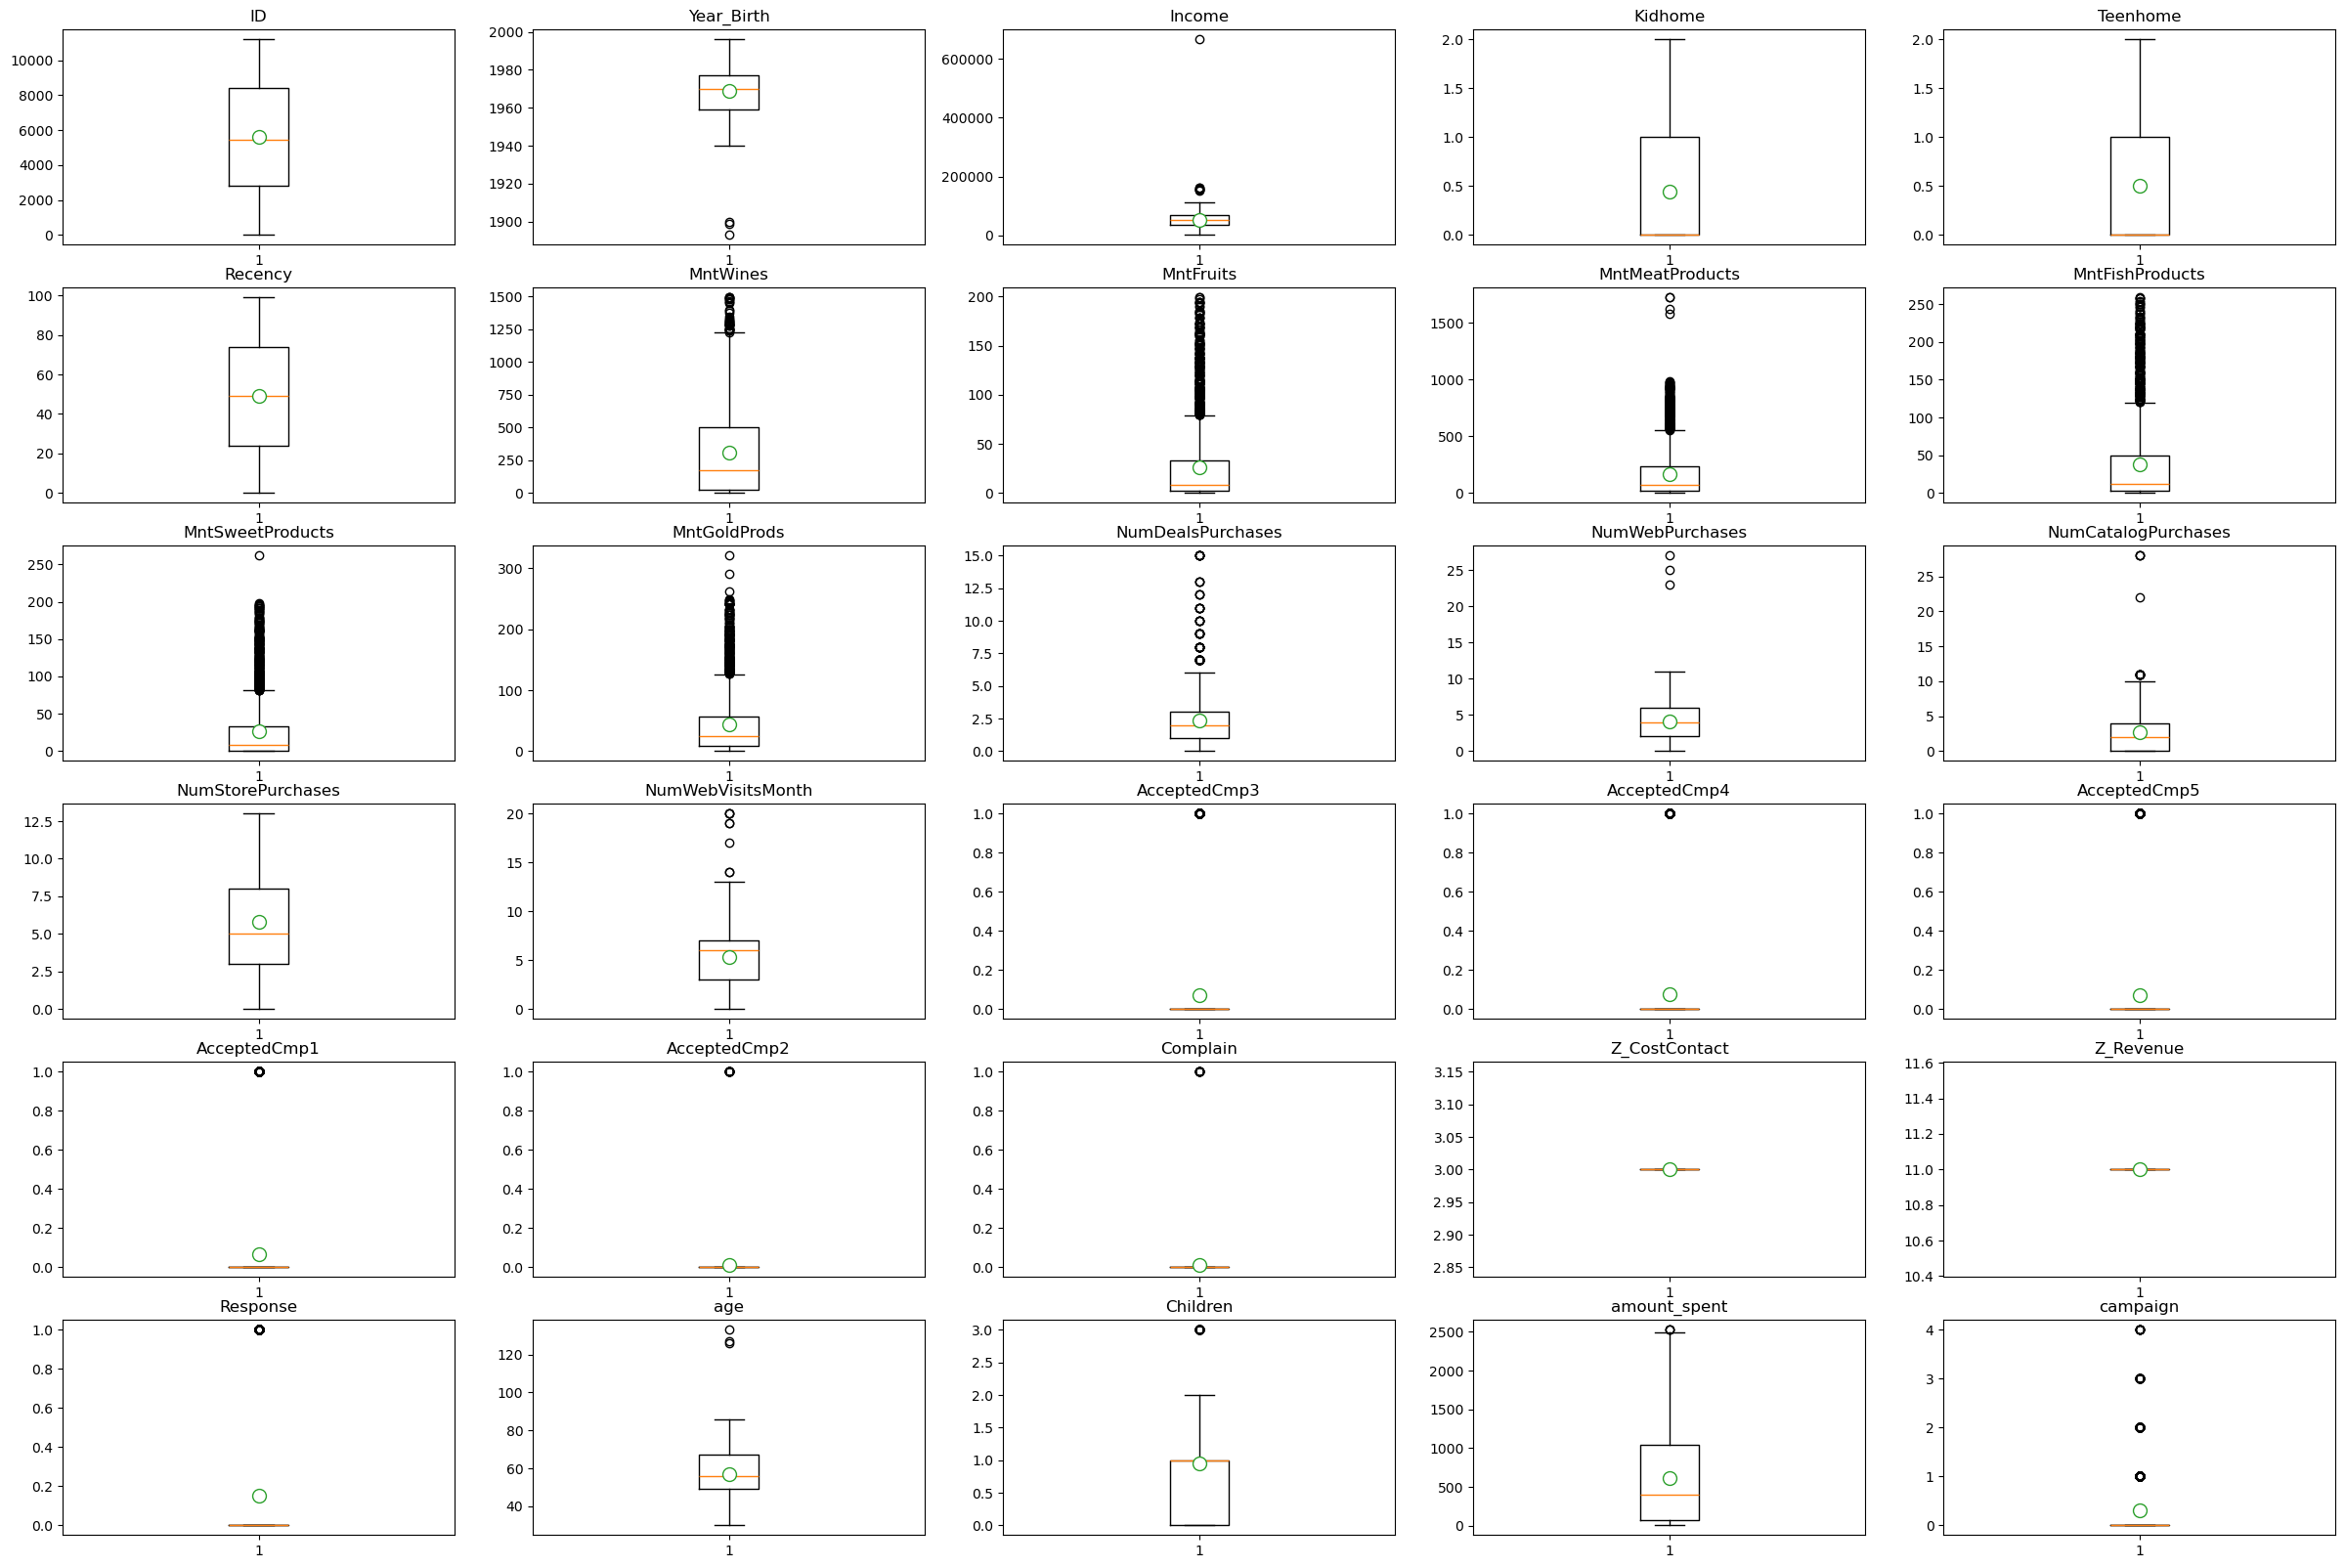

In [259]:

fig,axes= plt.subplots(ncols=5,nrows=6, figsize= (30,20))
axes= axes.reshape(-1)
for i,col in enumerate(df.select_dtypes(include=np.number)):
    axes[i].boxplot(df[col],showmeans= True,
                meanprops= {
                    "marker": "o",
                    "markerfacecolor": "White",
                    "markersize": "10"
                },)
    axes[i].set_title(col)

plt.show()
    

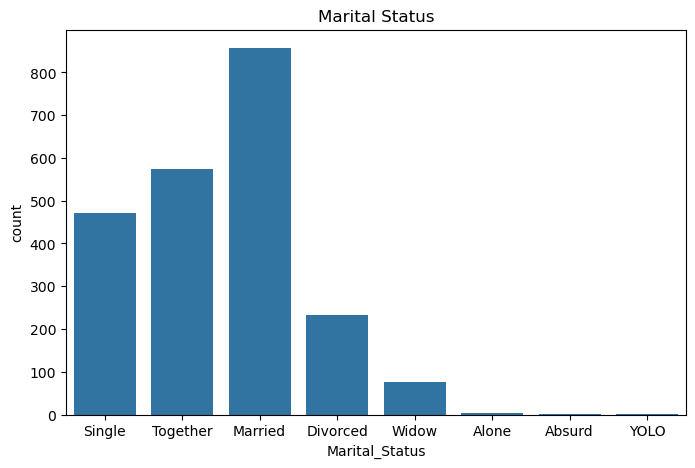

In [260]:
plt.figure(figsize=(8,5))
sns.countplot(data= df, x= 'Marital_Status')


plt.title('Marital Status')
plt.show()

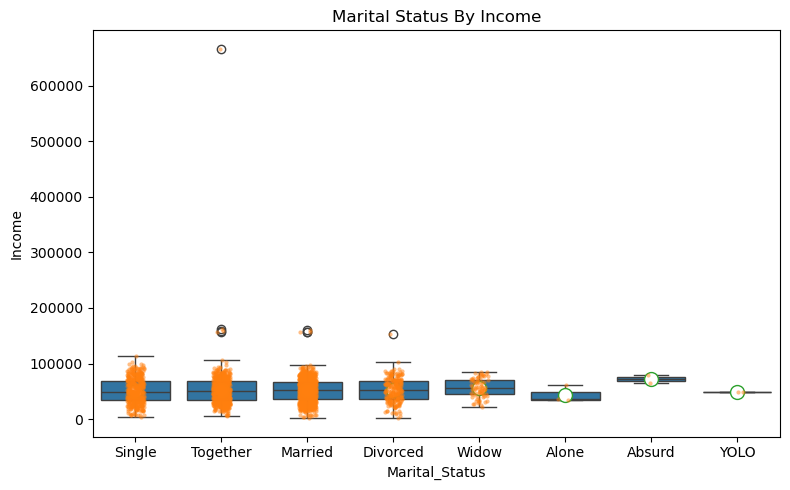

In [261]:
plt.figure(figsize=(8,5))

sns.boxplot(x='Marital_Status', y='Income', data=df,showmeans= True,
                meanprops= {
                    "marker": "o",
                    "markerfacecolor": "White",
                    "markersize": "10"
                },)
sns.stripplot(x='Marital_Status', y='Income', data=df,alpha=0.5,size=3,jitter=True)

plt.title('Marital Status By Income')
plt.tight_layout()
plt.show()

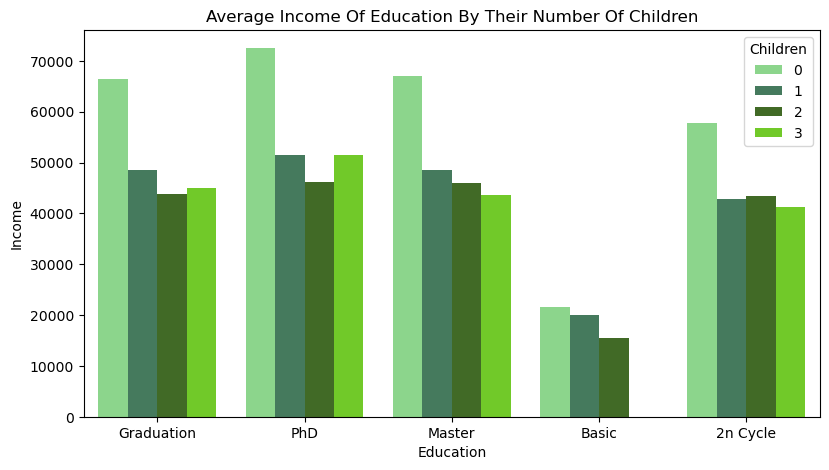

In [262]:
plt.figure(figsize=(8.4,4.6))
colors=["#80E180F8","#3C835CFF","#3F751BF9","#6FE30F"]
sns.barplot(data= df, x='Education', y='Income', estimator='mean', hue='Children',errorbar=None, palette=colors)

plt.tight_layout()
plt.title('Average Income Of Education By Their Number Of Children')
plt.show()

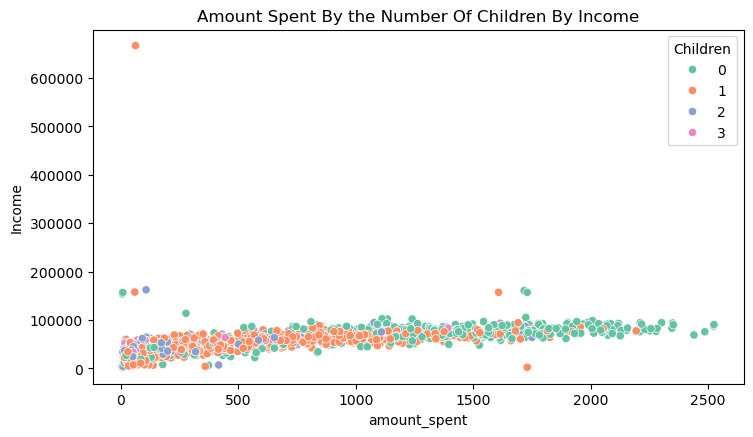

In [263]:
plt.figure(figsize=(8.4,4.6))

sns.scatterplot(data=df, y='Income', x='amount_spent', hue= 'Children', legend='full', palette='Set2')
plt.title('Amount Spent By the Number Of Children By Income')

plt.show()

In [264]:
df.Income.describe()

count      2216.000000
mean      52247.251354
std       25173.076661
min        1730.000000
25%       35303.000000
50%       51381.500000
75%       68522.000000
max      666666.000000
Name: Income, dtype: float64

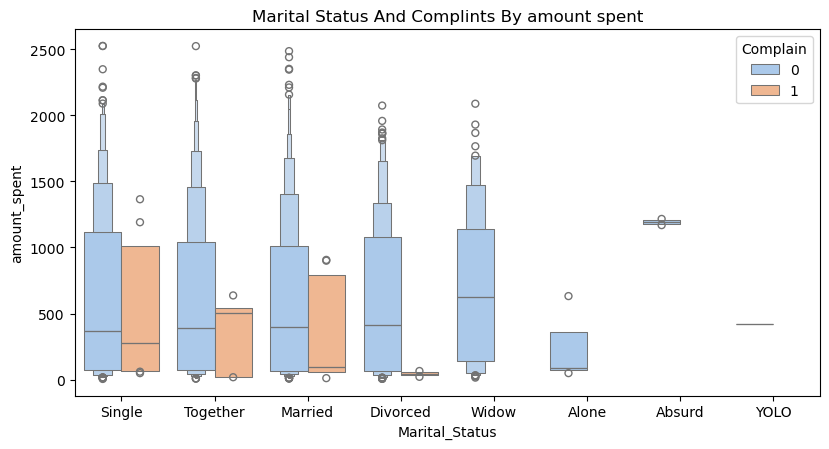

In [265]:
plt.figure(figsize=(8.4,4.6))

sns.boxenplot(data=df, x='Marital_Status', y='amount_spent', hue='Complain',palette='pastel')

plt.title('Marital Status And Complints By amount spent')
plt.tight_layout()
plt.show()

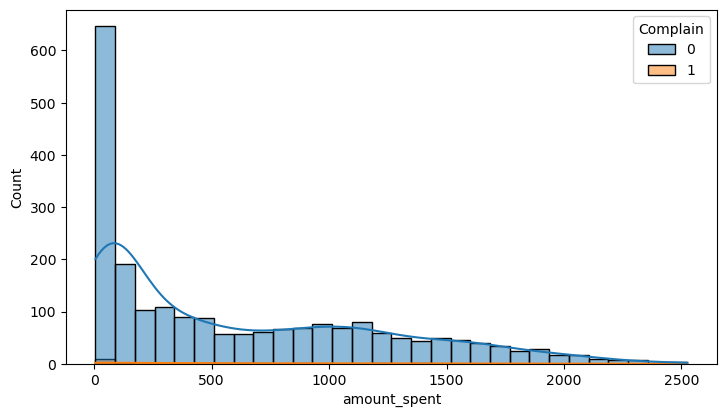

In [266]:
plt.figure(figsize=(8.4,4.6))

sns.histplot(data= df, hue= 'Complain', x='amount_spent', bins=30, kde= True)

plt.show()

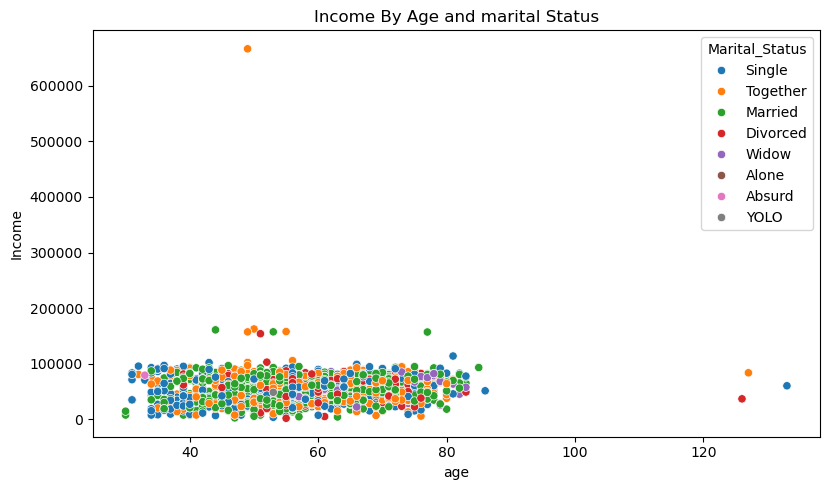

In [267]:
plt.figure(figsize=(8.4,5))

sns.scatterplot(data=df, x='age', y= 'Income', hue='Marital_Status')


plt.title('Income By Age and marital Status')
plt.tight_layout()
plt.show()

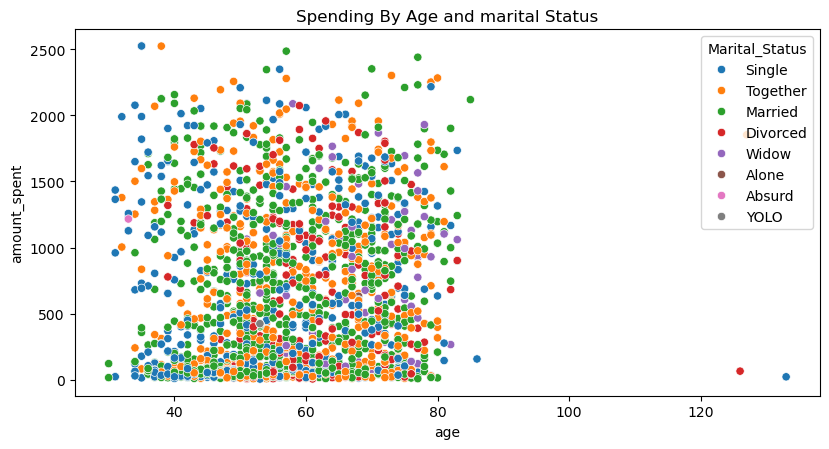

In [268]:
plt.figure(figsize=(8.4,4.6))


sns.scatterplot(data=df, x='age', y= 'amount_spent', hue='Marital_Status')
plt.title('Spending By Age and marital Status')
plt.tight_layout()
plt.show()

In [269]:
df[ 'Year_Birth'].value_counts().head()

Year_Birth
1976    89
1971    86
1975    83
1972    78
1978    76
Name: count, dtype: int64

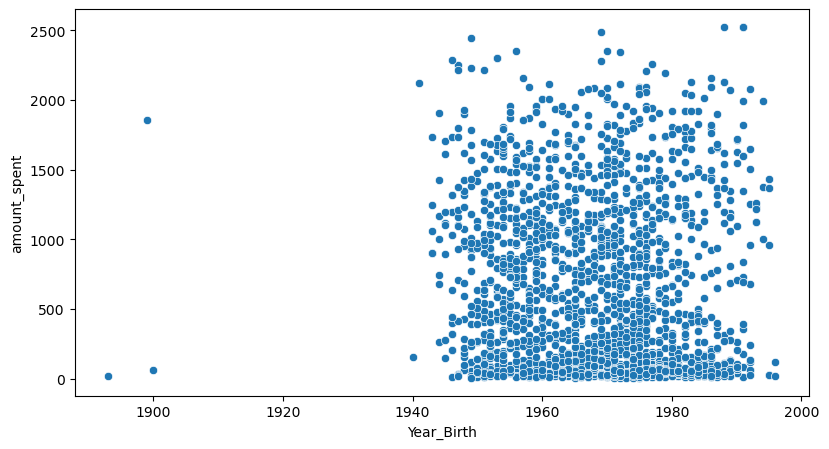

In [270]:
plt.figure(figsize=(8.4,4.6))

sns.scatterplot(data=df, x='Year_Birth', y= 'amount_spent')

plt.tight_layout()
plt.show()

In [271]:
df.set_index('Dt_Customer', inplace=True)

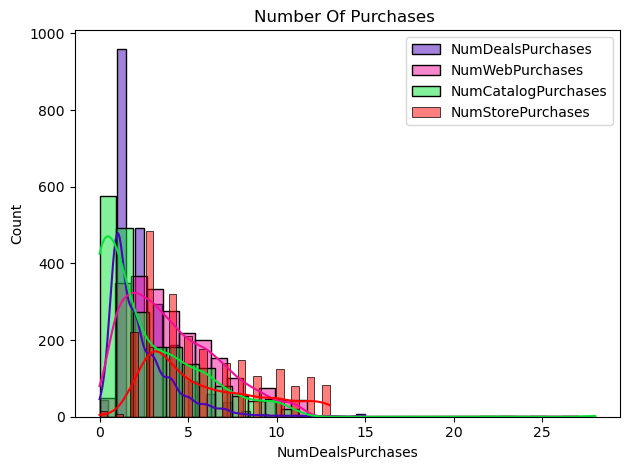

In [272]:
col= ['NumDealsPurchases', 'NumWebPurchases', 'NumCatalogPurchases','NumStorePurchases',]
colors= ["#4A04B9C3","#F20E9BFF","#08E437FF","#FF0101"]
for i,col in enumerate(col):
  sns.histplot(data=df, x=df[col], bins=30, kde=True, label=col, color=colors[i])
  plt.title("Number Of Purchases ")
plt.legend()
plt.tight_layout()
plt.show()

In [273]:
df.groupby('NumWebPurchases')['NumWebVisitsMonth'].agg(['mean','sum', 'count']).reset_index().head()

,NumWebPurchases,mean,sum,count
0,0,5.979167,287,48
1,1,6.232759,2169,348
2,2,5.714674,2103,368
3,3,5.131737,1714,334
4,4,4.104693,1137,277


In [274]:
df.Complain.value_counts()

Complain
0    2195
1      21
Name: count, dtype: int64

In [275]:
age_by_complain=df[df['Complain']== 1]
age_by_complain=age_by_complain[['age','Complain']].value_counts().reset_index().sort_values('count', ascending=False)
age_by_complain.head()

,age,Complain,count
0,67,1,3
2,48,1,2
1,72,1,2
10,38,1,1
15,42,1,1


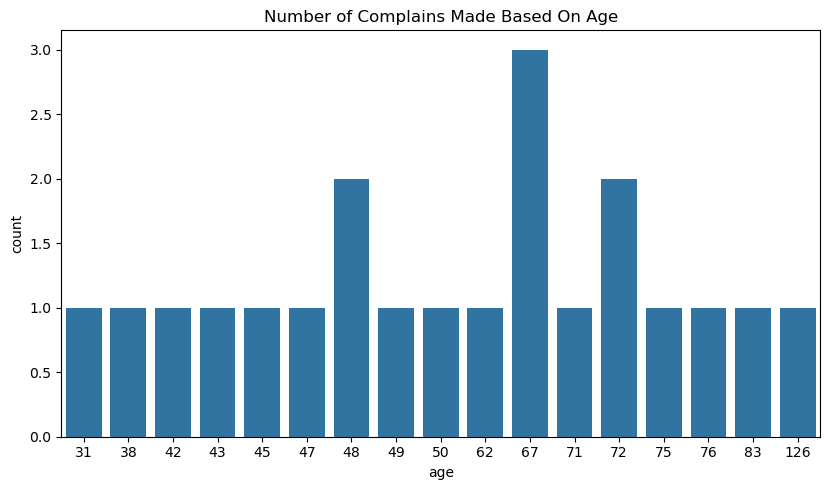

In [276]:
plt.figure(figsize=(8.4,5))

sns.barplot(data=age_by_complain, x='age', y='count')


plt.title('Number of Complains Made Based On Age')
plt.tight_layout()
plt.show()

In [277]:
df.groupby('Children')['amount_spent'].agg(['mean','sum','count'])

,mean,sum,count
Children,,,
0,1105.248025,699622,633
1,474.700090,530240,1117
2,246.735577,102642,416
3,255.500000,12775,50


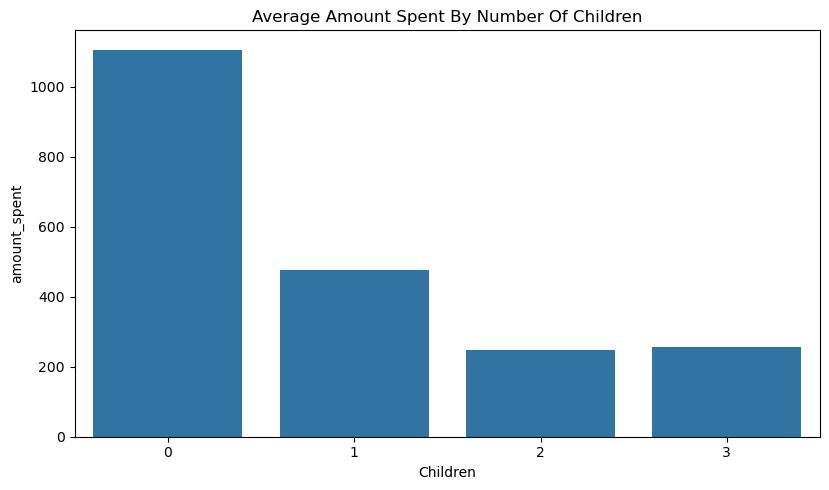

In [278]:
plt.figure(figsize=(8.4,5))

sns.barplot(data=df, y='amount_spent', x= 'Children', estimator='mean', errorbar=None)


plt.title('Average Amount Spent By Number Of Children')
plt.tight_layout()
plt.show()

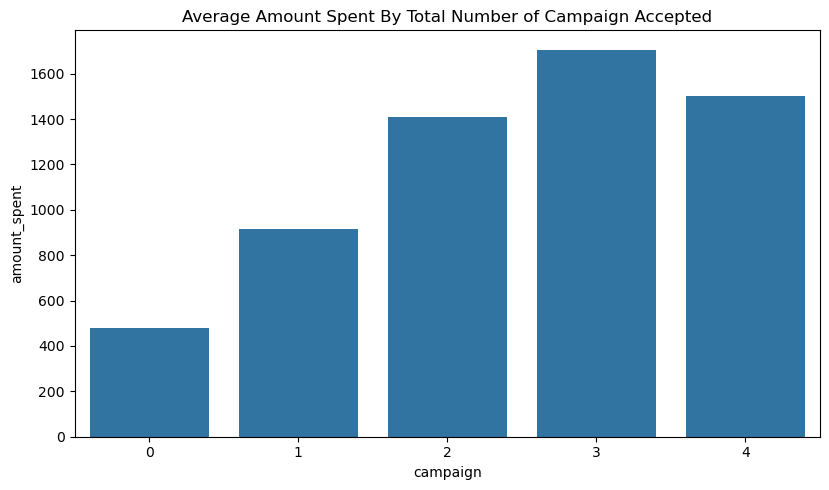

In [279]:
plt.figure(figsize=(8.4,5))

sns.barplot(data=df, y='amount_spent', x= 'campaign', estimator='mean', errorbar=None)


plt.title('Average Amount Spent By Total Number of Campaign Accepted')
plt.tight_layout()
plt.show()

In [280]:
df.groupby('Education')['amount_spent'].agg(['mean', 'count', 'sum']).reset_index()

,Education,mean,count,sum
0,2n Cycle,494.930000,200,98986
1,Basic,81.796296,54,4417
2,Graduation,621.686380,1116,693802
3,Master,609.767123,365,222565
4,PhD,676.733888,481,325509


In [281]:
df.groupby('Education')['Income'].agg(['mean', 'count', 'sum']).reset_index()

,Education,mean,count,sum
0,2n Cycle,47633.190000,200,9526638.0
1,Basic,20306.259259,54,1096538.0
2,Graduation,52720.373656,1116,58835937.0
3,Master,52917.534247,365,19314900.0
4,PhD,56145.313929,481,27005896.0


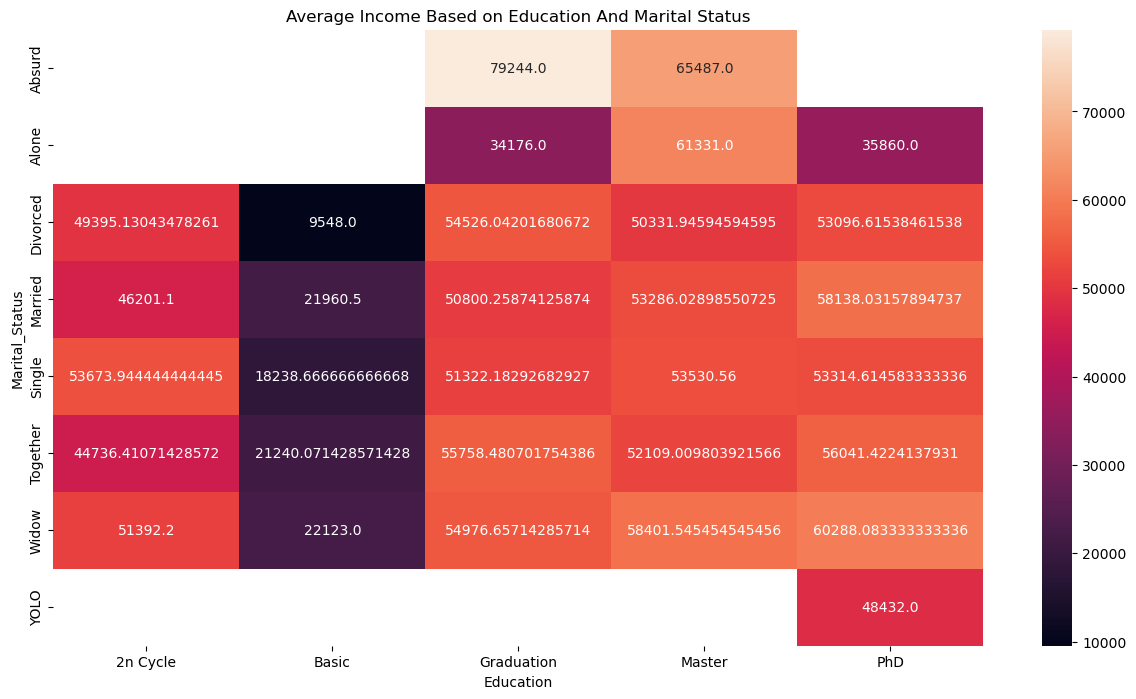

In [282]:
income=df.pivot_table(values='Income',columns='Education',index='Marital_Status', aggfunc='mean')
plt.figure(figsize=(15,8))
sns.heatmap(income, annot=True, fmt='')
plt.title("Average Income Based on Education And Marital Status")
plt.show()

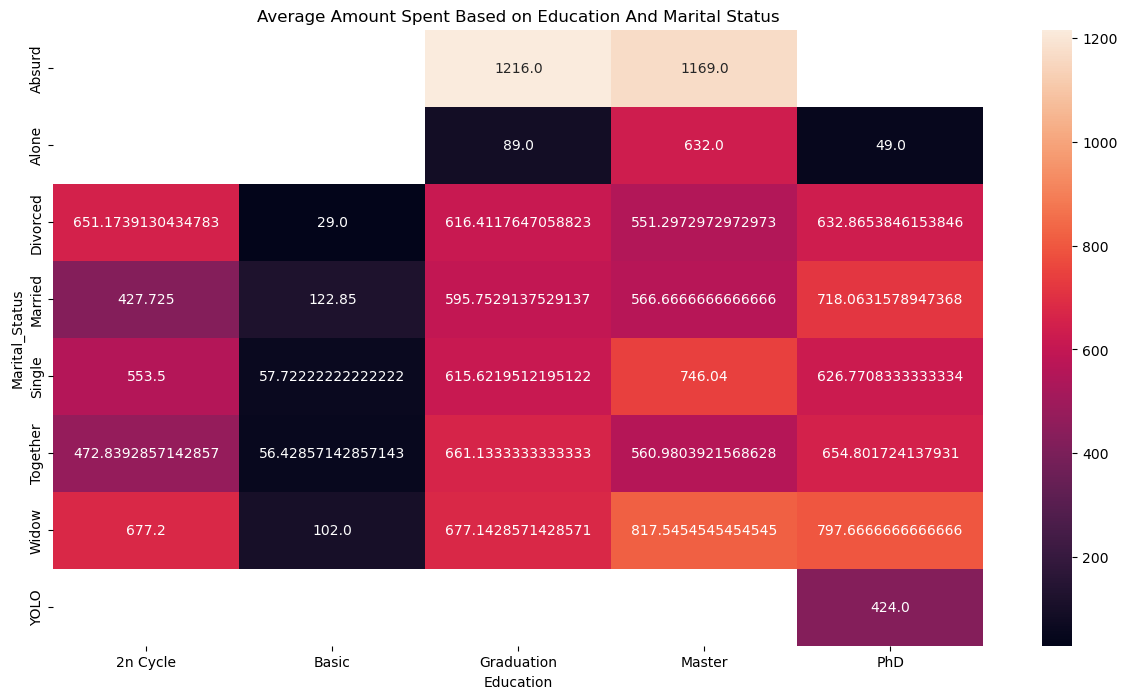

In [283]:
amount_spent=df.pivot_table(values='amount_spent',columns='Education',index='Marital_Status', aggfunc='mean')
plt.figure(figsize=(15,8))
sns.heatmap(amount_spent, annot=True, fmt='')
plt.title("Average Amount Spent Based on Education And Marital Status")
plt.show()

In [284]:
df.groupby('Education')[['NumDealsPurchases', 'NumWebPurchases', 'NumCatalogPurchases','NumStorePurchases']].agg(['mean', 'count', 'sum'])

NumDealsPurchases             NumWebPurchases              \
                        mean count   sum            mean count   sum   
Education                                                              
2n Cycle            2.260000   200   452        3.765000   200   753   
Basic               1.796296    54    97        1.888889    54   102   
Graduation          2.311828  1116  2580        4.115591  1116  4593   
Master              2.424658   365   885        4.035616   365  1473   
PhD                 2.359667   481  1135        4.432432   481  2132   

           NumCatalogPurchases             NumStorePurchases              
                          mean count   sum              mean count   sum  
Education                                                                 
2n Cycle              2.355000   200   471          5.560000   200  1112  
Basic                 0.481481    54    26          2.851852    54   154  
Graduation            2.738351  1116  3056          5.841398  1116  6519  
Master                2.545205   365   929          5.887671   365  2149  
PhD                   2.987526   481  1437          6.072765   481  2921

In [285]:
df['purchases']= df.NumCatalogPurchases + df.NumDealsPurchases + df.NumStorePurchases + df.NumWebPurchases

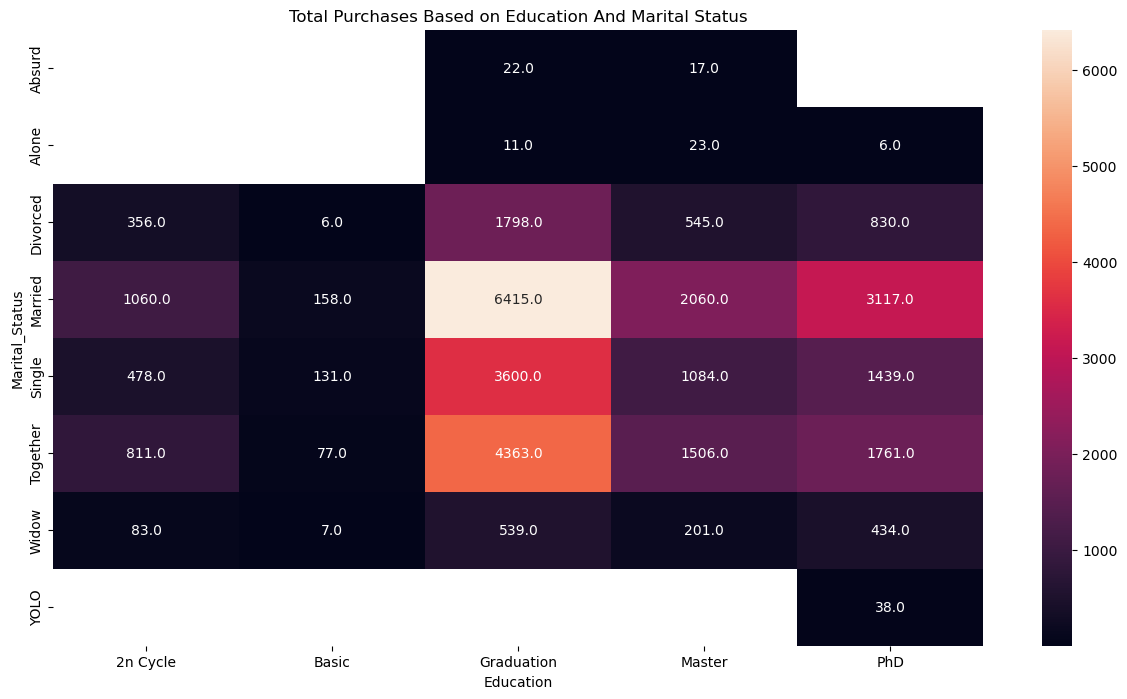

In [286]:
amount_spent=df.pivot_table(values='purchases',columns='Education',index='Marital_Status', aggfunc='sum')
plt.figure(figsize=(15,8))
sns.heatmap(amount_spent, annot=True, fmt='')
plt.title("Total Purchases Based on Education And Marital Status")
plt.show()

In [287]:
df.columns

Index(['ID', 'Year_Birth', 'Education', 'Marital_Status', 'Income', 'Kidhome',
       'Teenhome', 'Recency', 'MntWines', 'MntFruits', 'MntMeatProducts',
       'MntFishProducts', 'MntSweetProducts', 'MntGoldProds',
       'NumDealsPurchases', 'NumWebPurchases', 'NumCatalogPurchases',
       'NumStorePurchases', 'NumWebVisitsMonth', 'AcceptedCmp3',
       'AcceptedCmp4', 'AcceptedCmp5', 'AcceptedCmp1', 'AcceptedCmp2',
       'Complain', 'Z_CostContact', 'Z_Revenue', 'Response', 'age', 'Children',
       'amount_spent', 'campaign', 'purchases'],
      dtype='object')

In [292]:
df=df[['age','Education', 'Marital_Status', 'Income','amount_spent','purchases','NumWebVisitsMonth','campaign']]

In [294]:
df.head()

,age,Education,Marital_Status,Income,amount_spent,purchases,NumWebVisitsMonth,campaign
0,69,Graduation,Single,58138.0,1617,25,7,0
1,72,Graduation,Single,46344.0,27,6,5,0
2,61,Graduation,Together,71613.0,776,21,4,0
3,42,Graduation,Together,26646.0,53,8,6,0
4,45,PhD,Married,58293.0,422,19,5,0


In [295]:
df.describe()

,age,Income,amount_spent,purchases,NumWebVisitsMonth,campaign
count,2216.000000,2216.000000,2216.000000,2216.000000,2216.000000,2216.000000
mean,57.179603,52247.251354,607.075361,14.880866,5.319043,0.298285
std,11.985554,25173.076661,602.900476,7.670957,2.425359,0.679209
min,30.000000,1730.000000,5.000000,0.000000,0.000000,0.000000
25%,49.000000,35303.000000,69.000000,8.000000,3.000000,0.000000
50%,56.000000,51381.500000,396.500000,15.000000,6.000000,0.000000
75%,67.000000,68522.000000,1048.000000,21.000000,7.000000,0.000000
max,133.000000,666666.000000,2525.000000,44.000000,20.000000,4.000000


In [310]:
# Fixing outliers

def outlier(col):
  # Using z score
  outliers= []
  for i in df[col]:
    z_score = (i - df[col].mean())/ df[col].std()
    if np.abs(z_score) > 3:
      outliers.append(i)
  df[col]= df[col].where(df[df[col]in(outliers)],df[col].mean() )


In [311]:
outlier('income')

KeyError: 'income'